<a href="https://colab.research.google.com/github/Luiseg-ds/analisis-predictivo-PAES/blob/main/modelamiento_predictivo_resultados_PAES.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Carga de Datos y Preparación para el Modelamiento

En este segundo cuaderno importamos el dataset limpio y tratado (`dataset_paes_tratado.csv`), separamos las variables predictoras ($X$) de la variable objetivo ($y = \text{PAES\_M1\_Real}$), codificamos las variables categóricas y realizamos el particionamiento (*Train-Test Split*) para evitar el sobreajuste (*overfitting*).

In [ ]:
import pandas as pd
import numpy as np
import random
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ==========================================
# 1. CREACIÓN Y TRATAMIENTO DEL DATASET
# ==========================================
num_estudiantes = 109
np.random.seed(42)
random.seed(42)

df = pd.DataFrame()
df['ID_Estudiante'] = [f"EST_{i:03d}" for i in range(1, num_estudiantes + 1)]

tramos_paes = [
    (450, 499, 1), (550, 599, 3), (600, 649, 5), (650, 699, 8), (700, 749, 3),
    (750, 799, 9), (800, 849, 10), (850, 899, 12), (900, 949, 29), (950, 1000, 29)
]

puntajes_paes = []
for min_p, max_p, cantidad in tramos_paes:
    puntajes_paes.extend(np.random.randint(min_p, max_p + 1, cantidad))

np.random.shuffle(puntajes_paes)
df['PAES_M1_Real'] = puntajes_paes

df['Genero'] = np.random.choice(['Femenino', 'Masculino'], size=num_estudiantes, p=[0.52, 0.48])
prob_preu = np.where(df['PAES_M1_Real'] >= 850, 0.8, 0.4)
df['Preuniversitario'] = [np.random.choice(['Sí', 'No'], p=[p, 1-p]) for p in prob_preu]

df['Nota_NEM'] = df['PAES_M1_Real'] * 0.0028 + 4.2 + np.random.normal(0, 0.25, num_estudiantes)
df['Nota_NEM'] = df['Nota_NEM'].clip(4.0, 7.0).round(2)

def calcular_puntaje_nem(nota):
    if nota < 4.0: return 100
    elif nota < 5.0: return 100 + (nota - 4.0) * 315
    elif nota < 6.0: return 415 + (nota - 5.0) * 298
    elif nota <= 7.0: return 713 + (nota - 6.0) * 287
    else: return 1000

df['Puntaje_NEM'] = df['Nota_NEM'].apply(calcular_puntaje_nem).astype(int)

def calcular_ranking(row):
    bonificacion = (row['Nota_NEM'] - 5.4) * 110 + np.random.normal(0, 10)
    ranking_calc = row['Puntaje_NEM'] + bonificacion
    return int(np.clip(ranking_calc, 150, 1000))

df['Puntaje_Ranking'] = df.apply(calcular_ranking, axis=1)

df['Asistencia_Pct'] = df['PAES_M1_Real'] * 0.03 + 65 + np.random.normal(0, 5, num_estudiantes)
df['Asistencia_Pct'] = df['Asistencia_Pct'].clip(60, 100).round(1)

for i in range(1, 9):
    factor_crecimiento = 0.75 + (i * 0.03)
    puntaje_ensayo = df['PAES_M1_Real'] * factor_crecimiento + np.random.normal(0, 40, num_estudiantes)
    puntaje_ensayo = np.clip(puntaje_ensayo, 150, 1000)

    ausencias = np.random.choice([True, False], size=num_estudiantes, p=[0.15, 0.85])
    puntaje_ensayo[ausencias] = np.nan

    df[f'Ensayo_{i}'] = np.round(puntaje_ensayo)

columnas_ordenadas = ['ID_Estudiante', 'Genero', 'Preuniversitario',
                      'Nota_NEM', 'Puntaje_NEM', 'Puntaje_Ranking', 'Asistencia_Pct',
                      'Ensayo_1', 'Ensayo_2', 'Ensayo_3', 'Ensayo_4',
                      'Ensayo_5', 'Ensayo_6', 'Ensayo_7', 'Ensayo_8', 'PAES_M1_Real']
df = df[columnas_ordenadas]

# Tratamiento de datos (Imputación de nulos en ensayos por promedio individual)
columnas_ensayos = [col for col in df.columns if col.startswith('Ensayo_')]
promedios_individuales = df[columnas_ensayos].mean(axis=1)
for col in columnas_ensayos:
    df[col] = df[col].fillna(promedios_individuales)

print("Dataset listo y tratado. Valores nulos restantes:", df.isnull().sum().sum())


# ==========================================
# 2. MODELAMIENTO PREDICTIVO (MACHINE LEARNING)
# ==========================================
X = df.drop(columns=['ID_Estudiante', 'PAES_M1_Real'])
y = df['PAES_M1_Real']

# Codificación de variables categóricas
X = pd.get_dummies(X, columns=['Genero', 'Preuniversitario'], drop_first=True)

# División Train / Test (80% entrenamiento, 20% prueba)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Entrenamiento de Modelos
modelo_lr = LinearRegression()
modelo_lr.fit(X_train, y_train)

modelo_rf = RandomForestRegressor(n_estimators=100, random_state=42)
modelo_rf.fit(X_train, y_train)

# Predicciones y Evaluación
y_pred_lr = modelo_lr.predict(X_test)
y_pred_rf = modelo_rf.predict(X_test)

def evaluar_modelo(nombre, y_real, y_pred):
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    r2 = r2_score(y_real, y_pred)
    return pd.DataFrame({'Modelo': [nombre], 'MAE': [mae], 'RMSE': [rmse], 'R2': [r2]})

resultados = pd.concat([
    evaluar_modelo('Regresión Lineal', y_test, y_pred_lr),
    evaluar_modelo('Random Forest', y_test, y_pred_rf)
], ignore_index=True)

display(resultados)

Dataset listo y tratado. Valores nulos restantes: 0


,Modelo,MAE,RMSE,R2
0,Regresión Lineal,16.457015,21.111808,0.969022
1,Random Forest,18.092727,23.065264,0.963024


### 3. Interpretación del Modelo: Importancia de Variables (*Feature Importance*)

Una vez entrenado el modelo de **Random Forest**, el siguiente paso crucial desde la perspectiva analítica y educativa no es solo ver qué tan bien predice (métricas de error), sino **qué variables están impulsando esas predicciones**. Esto responde a la pregunta clave para los docentes y directivos: *¿Qué es lo que más pesa para asegurar un excelente resultado en la PAES M1?*

/tmp/ipykernel_610/2839502100.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_importancias.head(10), x='Importancia', y='Caracteristica', palette='viridis')


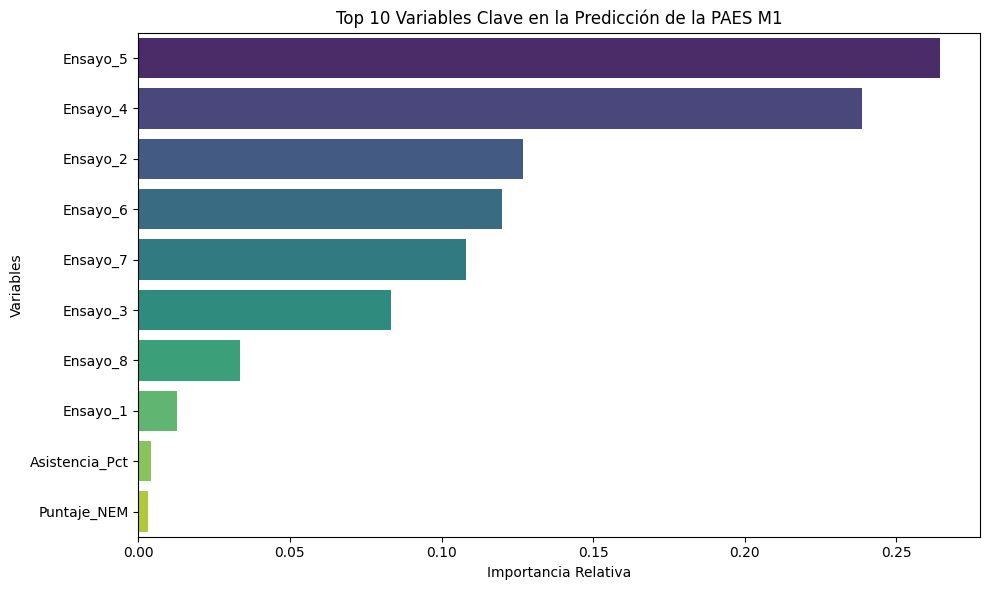

,Caracteristica,Importancia
8,Ensayo_5,0.264328
7,Ensayo_4,0.238761
5,Ensayo_2,0.126870
9,Ensayo_6,0.119933
10,Ensayo_7,0.108063
6,Ensayo_3,0.083285
11,Ensayo_8,0.033701
4,Ensayo_1,0.012797
3,Asistencia_Pct,0.004248
1,Puntaje_NEM,0.003078


In [ ]:
# 3. Análisis de Importancia de Variables (Feature Importance)
import matplotlib.pyplot as plt
import seaborn as sns

# Extraer importancias del modelo Random Forest entrenado
importancias = modelo_rf.feature_importances_
nombres_features = X_train.columns

df_importancias = pd.DataFrame({
    'Caracteristica': nombres_features,
    'Importancia': importancias
}).sort_values(by='Importancia', ascending=False)

# Visualización gráfica
plt.figure(figsize=(10, 6))
sns.barplot(data=df_importancias.head(10), x='Importancia', y='Caracteristica', palette='viridis')
plt.title('Top 10 Variables Clave en la Predicción de la PAES M1')
plt.xlabel('Importancia Relativa')
plt.ylabel('Variables')
plt.tight_layout()
plt.show()

# Mostrar el ranking en tabla
display(df_importancias.head(10))

### 🎯 4. Tabla de Predicciones y Alerta Temprana (SATE)

Para cerrar el ciclo del proyecto con un enfoque de impacto educativo real, traducimos las predicciones del modelo en una **herramienta de gestión escolar (Sistema de Alerta Temprana)**. Esto nos permite comparar el puntaje real con el predicho e identificar individualmente a los estudiantes que podrían requerir apoyo pedagógico prioritario.

In [ ]:
# 4. Consolidación de Predicciones y Detección de Riesgo
df_resultados = pd.DataFrame({
    'ID_Estudiante': df.loc[X_test.index, 'ID_Estudiante'],
    'Puntaje_Real': y_test,
    'Puntaje_Predicho': np.round(y_pred_rf)
})

# Calculamos el error residual y definimos un umbral de riesgo (ej: proyectar < 750 puntos)
df_resultados['Diferencia'] = df_resultados['Puntaje_Predicho'] - df_resultados['Puntaje_Real']
df_resultados['Alerta_Riesgo'] = df_resultados['Puntaje_Predicho'] < 750

# Visualizar los primeros casos del conjunto de prueba
display(df_resultados.head(10))

# Resumen ejecutivo para el equipo directivo
total_en_riesgo = df_resultados['Alerta_Riesgo'].sum()
print(f"\n--- REPORTE EJECUTIVO SATE ---")
print(f"Estudiantes evaluados en el conjunto de prueba: {len(df_resultados)}")
print(f"Estudiantes proyectados en zona de riesgo (<750 pts): {total_en_riesgo}")

,ID_Estudiante,Puntaje_Real,Puntaje_Predicho,Diferencia,Alerta_Riesgo
78,EST_079,622,600.0,-22.0,True
10,EST_011,974,944.0,-30.0,False
4,EST_005,903,922.0,19.0,False
84,EST_085,930,949.0,19.0,False
64,EST_065,934,930.0,-4.0,False
68,EST_069,774,753.0,-21.0,False
30,EST_031,941,950.0,9.0,False
45,EST_046,836,837.0,1.0,False
96,EST_097,815,814.0,-1.0,False
11,EST_012,779,822.0,43.0,False



--- REPORTE EJECUTIVO SATE ---
Estudiantes evaluados en el conjunto de prueba: 22
Estudiantes proyectados en zona de riesgo (<750 pts): 4
